# RaschPy for assessing Hate severity on Hate speech annotation task

In [3]:

%load_ext autoreload
%autoreload 0

In [1]:
def safe_rater_fit_statistics(self, info_df, kurtosis_df, residual_df, std_residual_df):
    outfit, infit, counts = {}, {}, {}
    for rater in self.raters:
        try:
            z2  = (std_residual_df ** 2).xs(rater)
            res = (residual_df ** 2).xs(rater)
            inf = info_df.xs(rater)
            counts[rater] = z2.count().sum()
            outfit[rater] = z2.sum().sum() / counts[rater]
            infit[rater]  = res.sum().sum() / inf.sum().sum()
        except KeyError:                      # rater has no usable rows
            counts[rater] = 0
            outfit[rater] = infit[rater] = float('nan')

    outfit_ms = pd.Series(outfit)
    infit_ms  = pd.Series(infit)
    nan = pd.Series(float('nan'), index=outfit_ms.index)
    return outfit_ms, nan, infit_ms, nan      # z-scores deliberately not computed

print("defined:", callable(safe_rater_fit_statistics))

defined: True


In [60]:
from pathlib import Path
import sys, os
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import RaschPy_aies 
from RaschPy_aies import RaschPy as rp
import importlib, RaschPy_aies.RaschPy as m
importlib.reload(m)

rp.MFRM.rater_fit_statistics = safe_rater_fit_statistics
print(rp.MFRM.rater_fit_statistics.__name__)
# importlib.reload(__init__)

import pandas as pd
import numpy as np
from itertools import combinations
from scipy import stats

import config
import importlib
import mfrm_analysis
importlib.reload(mfrm_analysis)
importlib.reload(config)


from config import DATA_DIR,DATA_DIR_MFRM,AGREE_OUTPUT_DIR_stats_nohs, DIMENSIONS, Figures, OUTPUT_modu_5runs, COLORS, LLM_NAMES, ANNOTATOR_ID_MAP, OUTPUT_modu_only, DATA_modu_only, DATA_modu_mfrm
from mfrm_analysis import read_filepaths, creating_mfrm_ready_data, plot_severity_strip, extract_single_run

# berkeley_dataset = load_dataset("ucberkeley-dlab/measuring-hate-speech")
# gold_original  = berkeley_dataset['train'].to_pandas()


safe_rater_fit_statistics
Config imported successfully!


# saving only the single modu runs

In [53]:
# Check annotator distribution in gold dataset
all_filepaths = read_filepaths(DATA_modu_only/'originals')
gold_dataset = pd.read_csv(all_filepaths['gold'], index_col=0)
gold_dataset.columns

annotator_counts = (
    gold_dataset[['comment_id', 'annotator_id']]
    .groupby('comment_id')['annotator_id']
    .count()
)
#collect only comments where raters >=2
index_rate_2 = annotator_counts[annotator_counts >= 2].index.tolist()
data_with_2raters_only = gold_dataset[gold_dataset['comment_id'].isin(index_rate_2)]

#extracting and saving only comment with 2+ raters for the ablation studt

all_data_2rater_dict = {}
for name, path in all_filepaths.items():
    data_name = f"{name}_2rater.csv"
    data = pd.read_csv(path)
    all_data_2rater = data[data['comment_id'].isin(index_rate_2)]
    all_data_2rater_dict[name] = all_data_2rater

    all_data_2rater.to_csv(DATA_modu_only/data_name, index=False)

print("Annotator count distribution:")
print(annotator_counts.value_counts(normalize=True).sort_index())
print(f"\nTotal comments        :        {len(annotator_counts):,}")
print(f"Comments with 2 annot   :        {(annotator_counts >= 2).sum()}")
print(f"Comments with 1 annot   :        {(annotator_counts == 1).sum()/len(annotator_counts):,}")
print(f"Comments with 2 annot   :        {(annotator_counts >= 2).sum()/len(annotator_counts):,}")
print(f"Comments with 3+ annot  :        {(annotator_counts >= 3).sum()/len(annotator_counts):,}")
print(f"Comments with 4+ annot  :        {(annotator_counts >= 4).sum()/len(annotator_counts):,}")
print(f"Mean annotators         :        {annotator_counts.mean():.2f}")

print('Extracting all comment from the gold dataset where rater >= 2')
print(index_rate_2)
print(data_with_2raters_only['comment_id'].nunique())
print(data_with_2raters_only.groupby('comment_id')['annotator_id'].nunique().min())

Annotator count distribution:
annotator_id
2    0.366492
3    0.408377
4    0.225131
Name: proportion, dtype: float64

Total comments        :        191
Comments with 2 annot   :        191
Comments with 1 annot   :        0.0
Comments with 2 annot   :        1.0
Comments with 3+ annot  :        0.6335078534031413
Comments with 4+ annot  :        0.225130890052356
Mean annotators         :        2.86
Extracting all comment from the gold dataset where rater >= 2
[364, 423, 545, 664, 801, 995, 1054, 1630, 2371, 2606, 2692, 3428, 3723, 4013, 4470, 4519, 4562, 4811, 4944, 5761, 6365, 6454, 6610, 6842, 7000, 7237, 7391, 7894, 8199, 8261, 8323, 8565, 8783, 9122, 9213, 9399, 9427, 9433, 9700, 9911, 10093, 10100, 10256, 10279, 10882, 10943, 11055, 11495, 11911, 12086, 12264, 13108, 13740, 13743, 14389, 14685, 15023, 15603, 15663, 16086, 16699, 17209, 17349, 17461, 17591, 17766, 17827, 17868, 18601, 18941, 18981, 19155, 19409, 19725, 20138, 20217, 20274, 20349, 20571, 21073, 22043, 22123, 227

In [54]:
# AGREE_OUTPUT_DIR_stats_nohs = OUTPUT_modu_only/ 'stats_modu_1run_testing2'
# os.makedirs(AGREE_OUTPUT_DIR_stats_nohs, exist_ok=True)

filepath_gold = all_filepaths['gold']
filepath_gpt5mini_modu= all_filepaths['gpt-5-mini_modu']
filepath_claude_modu= all_filepaths['claude_modu']
filepath_gemini_modu= all_filepaths['gemini_modu']
filepath_deepseek_modu= all_filepaths['deepseek_modu']

pd_dataframes, all_files, concat_df = creating_mfrm_ready_data(filepath_gold,
                                                               filepath_gpt5mini_modu, 
                                                               filepath_claude_modu, 
                                                               filepath_gemini_modu, 
                                                               filepath_deepseek_modu,
                                                               DATA_modu_mfrm) 

✓ Saved gold MFRM-ready data to: /Users/mikel/Library/CloudStorage/OneDrive-Personal/PHD 2021-2026/Fall_2026/FA26_MFRM_Judges/TRUST_2026/data_outputs_modu/data_modu/mfrm_single_results/mfrm_gold_ready_20261115_120836.csv
✓ Saved gpt-5-mini_modu MFRM-ready data to: /Users/mikel/Library/CloudStorage/OneDrive-Personal/PHD 2021-2026/Fall_2026/FA26_MFRM_Judges/TRUST_2026/data_outputs_modu/data_modu/mfrm_single_results/mfrm_gpt-5-mini_modu_ready_20261115_120836.csv
✓ Saved claude_modu MFRM-ready data to: /Users/mikel/Library/CloudStorage/OneDrive-Personal/PHD 2021-2026/Fall_2026/FA26_MFRM_Judges/TRUST_2026/data_outputs_modu/data_modu/mfrm_single_results/mfrm_claude_modu_ready_20261115_120836.csv
✓ Saved gemini_modu MFRM-ready data to: /Users/mikel/Library/CloudStorage/OneDrive-Personal/PHD 2021-2026/Fall_2026/FA26_MFRM_Judges/TRUST_2026/data_outputs_modu/data_modu/mfrm_single_results/mfrm_gemini_modu_ready_20261115_120836.csv
✓ Saved deepseek_modu MFRM-ready data to: /Users/mikel/Library/Clo

In [55]:
gold_dataset = pd_dataframes['gold']
gole_dataset_nohs = gold_dataset.drop(columns='hatespeech')
gole_dataset_nohs.columns #number of comment in the original gold dataset with duplicates

Index(['Unnamed: 0', 'text', 'comment_id', 'annotator_id', 'sentiment',
       'respect', 'insult', 'humiliate', 'status', 'dehumanize', 'violence',
       'genocide', 'attack_defend', 'hate_speech_score', 'annotator_severity',
       'annotator_infitms', 'annotator_outfitms'],
      dtype='object')

In [57]:
# base_dir_2 = Path(output_dir)
all_filepaths_2 = read_filepaths(DATA_modu_mfrm)


def calibrate(filepath, label):
    """Helper to load and calibrate MFRM model."""
    print(f"  Calibrating {label}...")
    data, _ = rp.loadup_mfrm_single(filepath)
    model   = rp.MFRM(data)
    model.calibrate_global()
    return model


gold_data            = str(all_filepaths_2['gold'])
gpt5mini_modu_data   = str(all_filepaths_2['gpt-5-mini_modu'])
claude_modu_data     = str(all_filepaths_2['claude_modu'])
gemini_modu_data     = str(all_filepaths_2['gemini_modu'])
deepseek_modu_data   = str(all_filepaths_2['deepseek_modu'])

human_gpt5mini_modu_data   = str(all_filepaths_2['human_gpt-5-mini_modu'])
human_claude_modu_data   = str(all_filepaths_2['human_claude_modu'])
human_gemini_modu_data   = str(all_filepaths_2['human_gemini_modu'])
human_deepseek_modu_data   = str(all_filepaths_2['human_deepseek_modu'])

llm_only_modu        = str(all_filepaths_2['llm_only_modu'])
llm_human_modu       = str(all_filepaths_2['llm_human_modu'])


# =============================================================================
# CALIBRATE SEPARATE MODELS WITH MFRM
# =============================================================================
print("\nCalibrating separate models...")

# Individual annotator models
mfrm_humans        = calibrate(gold_data,           'Humans only')
mfrm_gpt5mini_modu = calibrate(gpt5mini_modu_data,  'gpt-5-mini_modu')
mfrm_claude_modu   = calibrate(claude_modu_data,    'Claude modu')
mfrm_gemini_modu   = calibrate(gemini_modu_data,    'Gemini modu')
mfrm_deepseek_modu = calibrate(deepseek_modu_data,  'DeepSeek modu')

mfrm_human_gpt5mini_modu = calibrate(human_gpt5mini_modu_data,  'human_gpt-5-mini_modu')
mfrm_human_claude_modu   = calibrate(human_claude_modu_data,    'human_Claude modu')
mfrm_human_gemini_modu   = calibrate(human_gemini_modu_data,    'human_Gemini modu')
mfrm_human_deepseek_modu = calibrate(human_deepseek_modu_data,  'human_DeepSeek modu')

# Combined models
mfrm_llms_modu           = calibrate(llm_only_modu,      'All LLMs modu only')
mfrm_all                 = calibrate(llm_human_modu, 'All raters combined')

print("\n✓ All models calibrated")
# =============================================================================
# EXTRACT ITEM DIFFICULTIES and determing strictest and most lenient LLMs
# =============================================================================

comparison = pd.DataFrame({
    'humans'                 : mfrm_humans.diffs,
    'gpt5mini_modu'          : mfrm_gpt5mini_modu.diffs,
    'claude_modu'            : mfrm_claude_modu.diffs,
    'gemini_modu'            : mfrm_gemini_modu.diffs,
    'deepseek_modu'          : mfrm_deepseek_modu.diffs,
    'human_gpt5mini_modu'    : mfrm_human_gpt5mini_modu.diffs,
    'human_claude_modu'      : mfrm_human_claude_modu.diffs,
    'human_gemini_modu'      : mfrm_human_gemini_modu.diffs,
    'human_deepseek_modu'    : mfrm_human_deepseek_modu.diffs,
    'llm_only_modu'          : mfrm_llms_modu.diffs,
    'llm_human_modu'         : mfrm_all.diffs,

})

LLM_COLS = [col for col in comparison.columns if col in LLM_NAMES] #llm names only contains original llms names


# =============================================================================
# ITEM DIFFICULTY COMPARISONS
# =============================================================================
print("\n" + "="*80)
print("ITEM DIFFICULTY ANALYSIS")
print("="*80)

print("\n\n" + "="*300)
print("FULL ITEM DIFFICULTY COMPARISON TABLE")
print("="*300)
print(comparison.round(3).to_string())



Calibrating separate models...
  Calibrating Humans only...
  Calibrating gpt-5-mini_modu...
  Calibrating Claude modu...
  Calibrating Gemini modu...
  Calibrating DeepSeek modu...
  Calibrating human_gpt-5-mini_modu...
  Calibrating human_Claude modu...
  Calibrating human_Gemini modu...
  Calibrating human_DeepSeek modu...
  Calibrating All LLMs modu only...
  Calibrating All raters combined...

✓ All models calibrated

ITEM DIFFICULTY ANALYSIS


FULL ITEM DIFFICULTY COMPARISON TABLE
               humans  gpt5mini_modu  claude_modu  gemini_modu  deepseek_modu  human_gpt5mini_modu  human_claude_modu  human_gemini_modu  human_deepseek_modu  llm_only_modu  llm_human_modu
sentiment      -1.791         -1.953       -2.487       -2.920         -0.887               -1.778             -1.863             -1.925               -1.571         -2.127          -1.800
respect        -1.666         -1.253       -2.371       -2.259         -1.822               -1.593             -1.756            

In [62]:
mfrm_models = {
    'human_gpt5mini_modu': mfrm_human_gpt5mini_modu,
    'human_claude_modu': mfrm_human_claude_modu,
    'human_gemini_modu': mfrm_human_gemini_modu,
    'human_deepseek_modu': mfrm_human_deepseek_modu,
}

for item, mfrm in mfrm_models.items():
    stats_path = os.path.join(
        AGREE_OUTPUT_DIR_stats_nohs,
        f'item_stats_{item}_2raters_only.csv'
    )

    mfrm.item_stats_df_global()
    mfrm.item_stats_global.to_csv(stats_path, index=True)

In [61]:
# os.makedirs(OUTPUT_modu_only, exist_ok=True)
stats_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs, 'item_diff_stats_all_modu_noHS_2raters.csv')

mfrm_all.item_stats_df_global()
mfrm_all.item_stats_global.to_csv(stats_path, index=True)  # keep index for clarity
mfrm_all.item_stats_global

,Estimate,SE,Count,Facility,Infit MS,Outfit MS
sentiment,-1.800,0.102,1310,0.761,1.615,1.348
respect,-1.729,0.112,1272,0.718,1.633,1.529
insult,-0.669,0.099,1272,0.641,1.668,1.612
humiliate,-0.073,0.085,1272,0.594,1.889,2.114
status,-0.624,0.110,1267,0.703,1.771,4.521
dehumanize,0.921,0.106,1272,0.373,2.552,2.902
violence,2.018,0.151,1272,0.169,2.609,2.528
genocide,2.831,0.271,1272,0.068,2.618,2.182
attack_defend,-0.875,0.085,1272,0.684,1.564,2.362


In [10]:
# os.makedirs(OUTPUT_modu_only, exist_ok=True)
stats_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs, 'item_diff_stats_all_modu_2raters_only.csv')

mfrm_all.item_stats_df_global()
mfrm_all.item_stats_global.to_csv(stats_path, index=True)  # keep index for clarity
mfrm_all.item_stats_global

,Estimate,SE,Count,Facility,Infit MS,Outfit MS
sentiment,-1.947,0.087,1605,0.761,1.607,1.315
respect,-1.878,0.094,1526,0.721,1.549,1.407
insult,-0.879,0.078,1526,0.635,1.650,1.526
humiliate,-0.305,0.076,1525,0.593,1.813,1.933
status,-0.844,0.092,1519,0.704,1.681,4.224
dehumanize,0.770,0.073,1526,0.364,2.347,2.615
violence,1.661,0.121,1526,0.165,2.563,2.477
genocide,2.626,0.174,1526,0.063,2.413,2.211
attack_defend,-1.064,0.070,1526,0.684,1.528,2.260
hatespeech,1.859,0.105,1605,0.181,1.495,1.700


In [11]:
#compare with the human item statistics
human_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs, 'item_stats_human_only_2raters_noHS.csv') 
mfrm_humans.item_stats_df_global()
mfrm_humans.item_stats_global.to_csv(human_path, index=True) 
mfrm_humans.item_stats_global

,Estimate,SE,Count,Facility,Infit MS,Outfit MS
sentiment,-1.726,0.117,605,0.721,1.242,1.197
respect,-1.565,0.111,605,0.675,1.348,1.331
insult,-0.520,0.098,605,0.605,1.319,1.329
humiliate,0.105,0.104,605,0.542,1.514,1.541
status,-0.475,0.100,605,0.636,1.263,1.475
dehumanize,0.774,0.098,605,0.425,1.690,1.674
violence,1.574,0.158,605,0.198,1.897,1.662
genocide,2.263,0.251,605,0.100,1.773,1.581
attack_defend,-0.428,0.102,605,0.621,1.192,1.203


In [13]:
#compare with the llm only item statistics
llm_fit_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs, 'item_stats_llm_only_2raters_noHS.csv') 
mfrm_llms_modu.item_stats_df_global()
mfrm_llms_modu.item_stats_global.to_csv(llm_fit_path, index=True) 
mfrm_llms_modu.item_stats_global

,Estimate,SE,Count,Facility,Infit MS,Outfit MS
sentiment,-2.103,0.126,1000,0.785,1.833,1.474
respect,-2.065,0.116,921,0.751,1.349,0.838
insult,-1.087,0.121,921,0.656,1.217,0.954
humiliate,-0.525,0.116,920,0.626,1.188,1.061
status,-1.125,0.127,914,0.749,1.762,3.411
dehumanize,1.334,0.176,921,0.324,1.830,1.911
violence,2.624,0.254,921,0.143,1.612,0.962
genocide,4.578,0.417,921,0.039,1.405,0.700
attack_defend,-1.633,0.109,921,0.726,1.557,2.572


In [63]:
sep_reliability_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs, 'separation_reliabilitiy_mfrm_modu_only_noHS_2raters.csv') 
mfrm_all.test_stats_df_global()
mfrm_all.test_stats_global.to_csv(sep_reliability_path, index=True) 
mfrm_all.test_stats_global

,Items,Persons
Mean,-0.000,-0.347
SD,1.611,2.160
Separation ratio,11.797,7.017
Strata,16.062,9.690
Reliability,0.993,0.980


# rater severity(alpha[j]) with fit stats and plot/

In [64]:
# Apply patched raters fit statistics to avoid error from zero variance in the rater fit statistics calculation
rater_stats_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs, 'repatched_rater_statistics_noHS_2raters.csv')
mfrm_all.rater_stats_df_global()
repatched_rater_stats_df = mfrm_all.rater_stats_global
repatched_rater_stats_df.to_csv(rater_stats_path, index=True)
repatched_rater_stats_df.tail(10)

,Estimate,SE,Count,Infit MS,Outfit MS
Rater,,,,,
9902,-0.164,0.145,9,0.615,0.554
9914,1.548,0.283,9,1.641,1.064
9916,-1.197,0.203,9,0.855,0.888
9928,1.481,0.153,9,0.504,0.523
9971,-0.005,0.131,9,1.260,1.110
9982,1.463,0.124,9,2.306,2.067
claude_modu,-0.940,0.039,1594,1.895,1.586
deepseek_modu,-0.877,0.038,1663,2.527,2.176
gemini_modu,0.328,0.028,1663,1.739,1.888


## Plotting the raters severity 

human_infit>2 =30.0%,
human infit[0.5, 1.5]=40.0%,
humna_median_infit=1.417
Human severity quantiles: Q1=-1.110, Median=-0.053, Q3=1.284


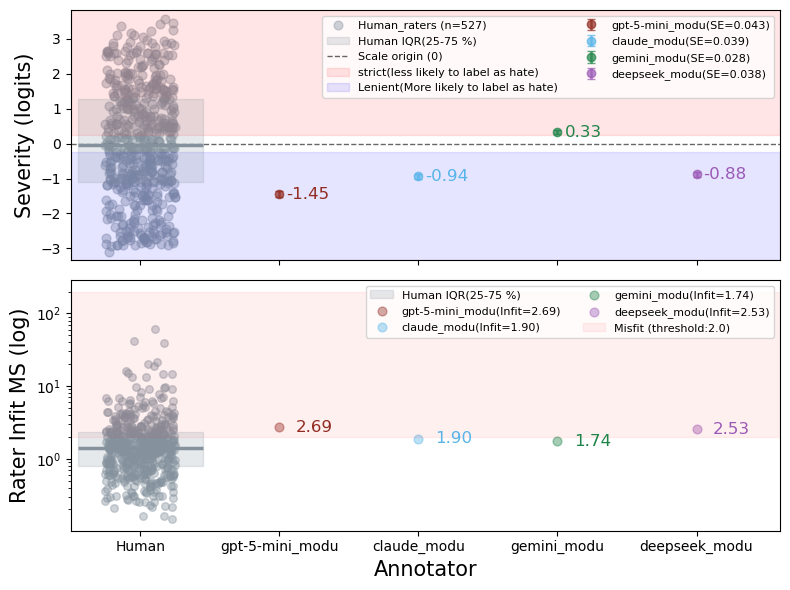

In [65]:
data_clean_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs, 'mfm_global_raters_stats_modu_noHS_repatched_2raters')
plot_severity_strip(repatched_rater_stats_df, OUTPUT_DIR=data_clean_path,colors=COLORS)

# Person's ability (theta[n])

The "Persons" in this table represent the specific comments in the dataset. Interpreting other columns:

**Estimate ($\theta_n$)**
This is the central output you are looking for—the **final continuous hate speech score** for each comment. It is calculated on a logit scale.
- Comment with highly positive estimate -->  it was rated as the most severe/hateful comment.
- Comment with highly negative estimate -->  it was rated as the least severe/hateful comment.

# threshold measurement 

In [21]:
mfrm_all.threshold_stats_df_global()
threshold_stats_one_run = mfrm_all.threshold_stats_global

threshold_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs, 'original_mfrm_all_threshold_modu_noHS_2raters.csv')
threshold_stats_one_run.to_csv(threshold_path, index=True)  # keep index
threshold_stats_one_run

,Estimate,SE,Infit MS,Outfit MS
Threshold 1,-1.552,0.129,1.208,1.773
Threshold 2,-1.092,0.075,1.695,3.072
Threshold 3,0.356,0.085,1.185,1.888
Threshold 4,2.287,0.118,1.229,1.578


## Get the hate scores with human only to compare with kennedy human only

In [20]:
# =============================================================================
# EXTRACT ALL THETAS
# =============================================================================
def extract_theta(mfrm, label=""):
    mfrm.person_stats_df_global()
    theta = mfrm.person_stats_global.get('Estimate')
    if theta is None or theta.empty:
        raise ValueError(f"No theta estimates found for: {label}")
    theta.index.name = 'comment_id'
    return theta

# ── Extract all thetas ────────────────────────────────────────────────────────
thetas = {
    'human'         : extract_theta(mfrm_humans,          'human'),
    'gpt-5-mini_modu' : extract_theta(mfrm_gpt5mini_modu, 'gpt-5-mini_modu'),
    'claude_modu'   : extract_theta(mfrm_claude_modu,     'claude_modu'),
    'gemini_modu'   : extract_theta(mfrm_gemini_modu,     'gemini_modu'),
    'deepseek_modu' : extract_theta(mfrm_deepseek_modu,   'deepseek_modu'),

    'human_gpt-5-mini_modu': extract_theta(human_mfrm_gpt5mini_modu,   'human_gpt-5-mini_modu'),
    'human_claude_modu'    : extract_theta(human_mfrm_claude_modu,     'human_claude_modu'),
    'human_gemini_modu'    : extract_theta(human_mfrm_gemini_modu,     'human_gemini_modu'),
    'human_deepseek_modu'  : extract_theta(human_mfrm_deepseek_modu,   'human_deepseek_modu'),

    'joint'         : extract_theta(mfrm_all,             'All raters combined'),
    'llm_only_modu' : extract_theta(mfrm_llms_modu,       'llm_modu_only'),
}

all_theta_df = pd.DataFrame(thetas)
theta_path = os.path.join(AGREE_OUTPUT_DIR_stats_nohs , 'all_theta_estimates_noHS.csv')
all_theta_df.to_csv(theta_path, index=True)

NameError: name 'human_mfrm_gpt5mini_modu' is not defined

In [ ]:
all_theta_df.head()